# Scenes

You will build: a planet orbiting its sun, moved from Python frame by frame, then a title card and a growing
bar chart kept as named clips in one file and rendered to video from the command line.

Run it from this folder with ``python scenes.py`` (writes SVG stills), or render the clips::

    python -m svgwriter animate scenes.py --list
    python -m svgwriter animate scenes.py Orbit --format gif

In [1]:
import math

import svgwriter as svg

A scene is a class: its settings give the size, frame rate and length, and `build` draws the first frame.

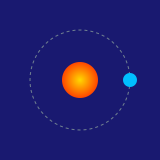

In [2]:
ORBIT = 50


class Orbit(svg.Scene):
    width = height = 160
    fps = 24
    duration = 2.0

    def build(self, doc: svg.Document) -> None:
        center = self.width / 2
        glow = doc.radial_gradient(svg.Stop(0, "gold"), svg.Stop(1, "orangered"))
        doc.rect(0, 0, self.width, self.height, fill="midnightblue")
        doc.circle(center, center, ORBIT, fill="none", stroke="slategray", stroke_dasharray=(3, 3))
        doc.circle(center, center, 18, fill=glow)
        self.planet = doc.circle(center + ORBIT, center, 7, fill="deepskyblue")

    def update(self, seconds: float) -> None:
        angle = 2 * math.pi * seconds / self.duration
        center = self.width / 2
        self.planet.cx = center + ORBIT * math.cos(angle)
        self.planet.cy = center + ORBIT * math.sin(angle)


orbit = Orbit()
orbit

`update(seconds)` moves things for a given moment: a quarter of the way through, the planet is a quarter round.

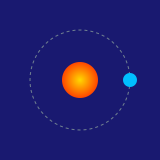

In [3]:
orbit.update(Orbit.duration / 4)
orbit

## Several scenes in one file

Scenes can share a base class. Its name starts with `_`, so it is not rendered as a clip of its own.

In [4]:
INK = "#1f2937"
PAPER = "#f8fafc"
ACCENT = "#0ea5e9"


class _Card(svg.Scene):
    width, height = 320, 180
    fps = 24

    def build(self, doc: svg.Document) -> None:
        doc.rect(0, 0, self.width, self.height, fill=PAPER)

`Title` needs no `update`: the ready-made animations from the previous example are enough.

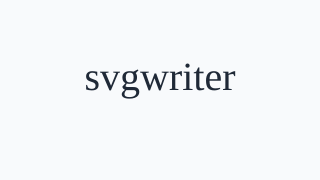

In [5]:
class Title(_Card):
    def build(self, doc: svg.Document) -> None:
        super().build(doc)
        title = doc.text("svgwriter", x=self.width / 2, y=90, font_size=40, fill=INK, text_anchor="middle")
        title.animate.fade_in(1)
        rule = doc.line(60, 110, 260, 110, stroke=ACCENT, stroke_width=4)
        rule.animate.draw(1.5)


Title()

`Bars` grows a chart from Python: `update` sets each bar's height for the moment it is given.

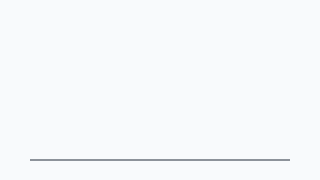

In [6]:
VALUES = (0.4, 0.9, 0.6, 0.75)
BAR = 40
GAP = 25
BASELINE = 160
TALLEST = 140


class Bars(_Card):
    duration = 1.5

    def build(self, doc: svg.Document) -> None:
        super().build(doc)
        doc.line(30, BASELINE, 290, BASELINE, stroke=INK)
        self.bars = [doc.rect(50 + i * (BAR + GAP), BASELINE, BAR, 0, fill=ACCENT) for i in range(len(VALUES))]

    def update(self, seconds: float) -> None:
        progress = min(seconds / self.duration, 1.0)
        for bar, value in zip(self.bars, VALUES, strict=True):
            height = value * TALLEST * progress
            bar.y = BASELINE - height
            bar.height = height


bars = Bars()
bars.update(Bars.duration)
bars

`scene.save("clip.mp4")` makes a video (`.gif` and `.webm` too); `python -m svgwriter animate` does
the same for every scene in the file. Here each scene is saved as an SVG still.
Next: [17 Behaviors](../17_behaviors/behaviors.py).

In [7]:
if __name__ == "__main__":
    orbit.update(0)
    for scene in (orbit, Title(), bars):
        scene.document.save(f"16_{scene.name}.svg")